# Example 2 — Branching DAGs, rulegraph & Mermaid

A workflow with multiple samples that merge into one output. We compare three ways to visualize it: the full DAG, the condensed **rulegraph**, and native **Mermaid** rendering.

In [1]:
print(open("Snakefile").read())

# Example 2 — a slightly larger workflow to show a branching DAG
#
# Two independent inputs are created, then merged.

SAMPLES = ["a", "b"]

rule all:
    input:
        "merged.txt",

rule make_sample:
    output:
        "sample_{sample}.txt",
    shell:
        "echo 'data for {wildcards.sample}' > {output}"

rule merge:
    input:
        expand("sample_{sample}.txt", sample=SAMPLES),
    output:
        "merged.txt",
    shell:
        "cat {input} > {output}"



## 1. Full DAG (one node per job)

Building DAG of jobs...


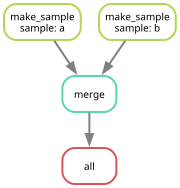

In [2]:
from IPython.display import SVG, display

!snakemake --dag | dot -Tsvg > dag.svg
display(SVG("dag.svg"))

## 2. Rulegraph (one node per rule — scales better)

Building DAG of jobs...


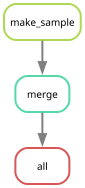

In [3]:
!snakemake --rulegraph | dot -Tsvg > rulegraph.svg
display(SVG("rulegraph.svg"))

## 3. Mermaid output

Snakemake 8 can emit the DAG as Mermaid. JupyterLab 4+ renders Mermaid natively in **Markdown** cells, so run the cell below, then paste its output into a Markdown cell wrapped in a ```` ```mermaid ```` fence.

In [4]:
# --dag-format mermaid requires Snakemake >= 8
!snakemake --dag --dag-format mermaid

usage: snakemake [-h] [--dry-run] [--profile PROFILE]
                 [--workflow-profile WORKFLOW_PROFILE] [--cache [RULE ...]]
                 [--snakefile FILE] [--cores N] [--jobs N] [--local-cores N]
                 [--resources NAME=INT [NAME=INT ...]]
                 [--set-threads RULE=THREADS [RULE=THREADS ...]]
                 [--max-threads MAX_THREADS]
                 [--set-resources RULE:RESOURCE=VALUE [RULE:RESOURCE=VALUE ...]]
                 [--set-scatter NAME=SCATTERITEMS [NAME=SCATTERITEMS ...]]
                 [--set-resource-scopes RESOURCE=[global|local] [RESOURCE=[global|local] ...]]
                 [--default-resources [NAME=INT ...]]
                 [--preemptible-rules [PREEMPTIBLE_RULES ...]]
                 [--preemptible-retries PREEMPTIBLE_RETRIES]
                 [--configfile FILE [FILE ...]] [--config [KEY=VALUE ...]]
                 [--replace-workflow-config] [--envvars VARNAME [VARNAME ...]]
                 [--directory DIR] [--touch] 